# Section 3: Analysis & Visualization

Reproduce paper Table I and Figure 3 from the canonical VOO summary files.
Mostly read-only over `canonical/voo_summaries/`.

**Source**: `notebook/ae_test/experiment1_real.ipynb` cells 33-44
**Paper**: arXiv:2604.08636v1 §V (Experiments), Table I, Figure 3

## What you get
- **Table I**: per-motion mean(min) ± std for Baseline/DH/Ours (Screw) × 3 motions, plus Motion Set
- **Figure 3**: 2D latent embedding with k=5 clusters + representative robots (matches paper)

## Safety
- Read-only over `canonical/voo_summaries/` and `canonical/data/`
- No writes unless `SAVE_OUTPUTS=True` (then writes to `./outputs/`)


In [1]:
# ---- Tutorial flags ----
SAVE_OUTPUTS = False

# ---- Path setup ----
import os, sys
HERE = os.path.abspath('.')
REPO = os.path.abspath('../../')
for p in ['package','package/yoon','package/mujoco_helper','package/kinematics_helper',
          'package/utility','package/bvh_helper','package/smpl','package/motion_retarget',
          'package/irvae_tools','package/kinematics','asset']:
    sys.path.insert(0, os.path.join(REPO, p))
sys.path.insert(0, HERE)

CANONICAL    = os.path.join(HERE, 'canonical/')
TUTORIAL_OUT = os.path.join(HERE, 'outputs/')
if SAVE_OUTPUTS:
    os.makedirs(TUTORIAL_OUT, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print(f'SAVE_OUTPUTS = {SAVE_OUTPUTS}')
print(f'canonical voo_summaries: {os.path.join(CANONICAL, "voo_summaries")}')

SAVE_OUTPUTS = False
canonical voo_summaries: <LEGO_code>/notebook/tutorial/canonical/voo_summaries


## 1. Table I reproduction

Per-motion mean(min) ± std across 10 seeds, for Baseline (120D direct search) / DH / Ours (Screw).
Plus Motion Set column = sum-of-3-motion PA-MPJPE + joint penalty (once).

Paper Table I values (for reference):

| Method | Wave Hello | Chicken Dance | Swimming | Motion Set |
|---|---|---|---|---|
| Baseline 120D | 152.2 ± 13.9 | 153.0 ± 10.2 | 154.8 ± 15.4 | 274.4 ± 33.9 |
| DH | 162.1 ± 17.4 | 148.8 ± 17.3 | 150.9 ± 20.9 | 315.8 ± 27.3 |
| Ours (Screw) | 97.5 ± 3.6 | 100.6 ± 5.0 | 101.3 ± 3.6 | 178.4 ± 10.8 |

In [2]:
TAGS = ['Screw-120D', 'dh', 'screw']
TAG_LABEL = {'Screw-120D': 'Baseline 120D', 'dh': 'DH [37]', 'screw': 'Ours (Screw)'}
MOTIONS = ['easy', 'middle', 'hard']
MOTION_LABEL = {'easy': 'Wave Hello', 'middle': 'Chicken Dance', 'hard': 'Swimming'}

def read_summary(motion, tag):
    p = os.path.join(CANONICAL, 'voo_summaries', f'{motion}_motion_{tag}', 'summary.npz')
    if not os.path.exists(p):
        return None
    d = np.load(p, allow_pickle=True)
    return float(d['mean_min']), float(d['std_min_sample']), float(d['global_y_min'])

def read_motion_set(tag):
    p = os.path.join(CANONICAL, 'voo_summaries', f'all_{tag}', 'summary.npz')
    if not os.path.exists(p):
        return None
    d = np.load(p, allow_pickle=True)
    return float(d['mean_min']), float(d['std_min_sample']), float(d['global_y_min'])

# Build the table
rows = []
for tag in TAGS:
    row = {'Method': TAG_LABEL[tag]}
    for m in MOTIONS:
        r = read_summary(m, tag)
        row[MOTION_LABEL[m]] = f'{r[0]:.2f} ± {r[1]:.2f}' if r else 'n/a'
    ms = read_motion_set(tag)
    row['Motion Set'] = f'{ms[0]:.2f} ± {ms[1]:.2f}' if ms else 'n/a'
    rows.append(row)

df = pd.DataFrame(rows).set_index('Method')
print('Table I (results reported in the paper):')
print(df.to_string())

# LaTeX export
print('\n--- LaTeX ---')
print(df.to_latex(escape=False))

Table I (results reported in the paper):
                   Wave Hello   Chicken Dance        Swimming      Motion Set
Method                                                                       
Baseline 120D  152.24 ± 13.95  153.05 ± 10.27  154.88 ± 15.45  274.44 ± 33.94
DH [37]        162.14 ± 17.45  148.81 ± 17.33  150.98 ± 20.90  315.88 ± 27.39
Ours (Screw)     97.50 ± 3.68   100.65 ± 5.07   101.30 ± 3.60  178.46 ± 10.88

--- LaTeX ---
\begin{tabular}{lllll}
\toprule
 & Wave Hello & Chicken Dance & Swimming & Motion Set \\
Method &  &  &  &  \\
\midrule
Baseline 120D & 152.24 ± 13.95 & 153.05 ± 10.27 & 154.88 ± 15.45 & 274.44 ± 33.94 \\
DH [37] & 162.14 ± 17.45 & 148.81 ± 17.33 & 150.98 ± 20.90 & 315.88 ± 27.39 \\
Ours (Screw) & 97.50 ± 3.68 & 100.65 ± 5.07 & 101.30 ± 3.60 & 178.46 ± 10.88 \\
\bottomrule
\end{tabular}



## 2. Figure 3 reproduction: Latent map of 30 robots (k=5)

Encode 30 training robots into the learned 2D latent space, cluster with k-means (k=5),
overlay robot labels. Matches paper Figure 3.

Encoded 30 robots → 2D latent


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


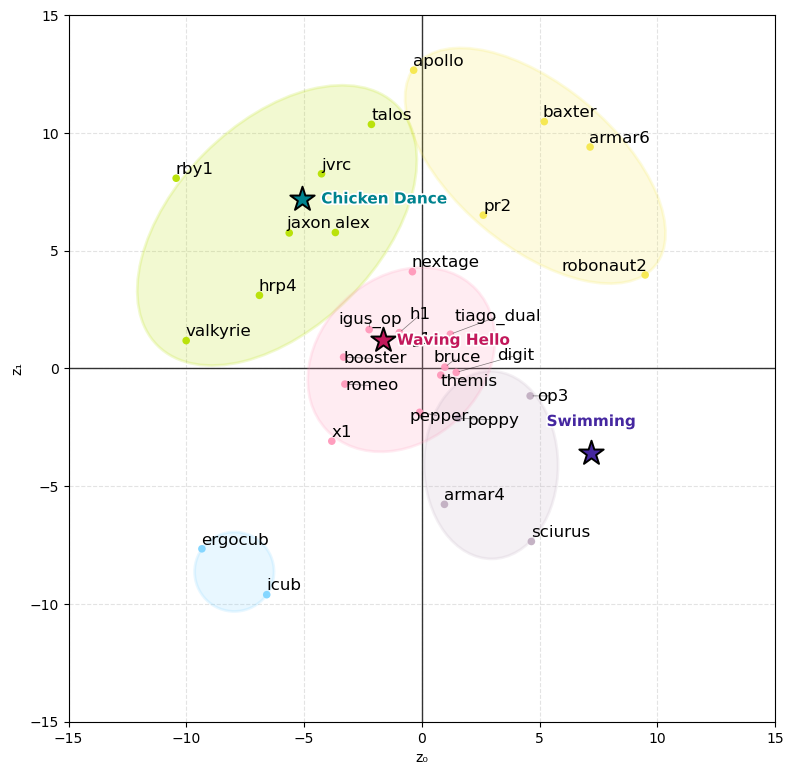

In [4]:
from data_utils import load_saved_model, load_data_subset
from sklearn.cluster import KMeans
from matplotlib.patches import Ellipse
import matplotlib.patheffects as pe
from adjustText import adjust_text
import torch as th

# ---------------- load data + AE + encode ----------------
repr_kind = 'screw'
data_path = os.path.join(CANONICAL, 'data', repr_kind) + '/'
data = load_data_subset(data_path)
labels = np.load(os.path.join(CANONICAL, 'data', repr_kind, 'label.npy'))
names = [str(s) for s in labels]

ae, _ = load_saved_model(model_name='h64_32_z2_isoTrue_actvTanh_isoreg1e-07_nepoch1000_bs10', device='cpu')
with th.no_grad():
    Z = ae.encode(th.tensor(data, dtype=th.float32)).numpy()
print(f'Encoded {len(Z)} robots → 2D latent')

# ---------------- canonical optimal points (experiment1_real.ipynb cell 51) ----------------
# These are the latent coords used to decode the three hardware prototypes (paper Fig 4).
# Optimal latent coords: from x_sel_*.npy files (user-selected "best for hardware" picks).
# Filename suffix is the PA-MPJPE+jnt_penalty value at that x.
# These match the paper Fig 4 hardware-prototype derivation (selected per motion under
# manufacturability constraints), not the algorithm's global VOO minimum.
# Optimal latent coords for the three HARDWARE PROTOTYPES (paper Fig 4).
# Source: project Notion / author records. These are NOT the VOO algorithm's global
# minima: they were manually selected as "best feasible designs under manufacturability
# constraints", per paper §V-F: "our decoder and search do not yet enforce hard
# manufacturability constraints ... permitted local position adjustments up to 10mm".
#
# Cross-check: these coordinates do NOT match x_sel_*.npy, x_global_*.npy, or
# summary.npz global_y_min: they are a separate set authored for hardware build.
OPTIMALS = {
    'easy':   {'x': np.array([-1.6619777575085908,  1.198941368585525]),
               'label': 'Waving Hello',    'color': '#C2185B',
               'offset': (0.6, 0.0),  'ha': 'left',  'va': 'center'},
    'middle': {'x': np.array([-5.0757112738430035,  7.200598275418453]),
               'label': 'Chicken Dance', 'color': '#00838F',
               'offset': (0.8, 0.0),  'ha': 'left',  'va': 'center'},
    'hard':   {'x': np.array([ 7.179852691307394, -3.569850905850164]),
               'label': 'Swimming',         'color': '#4527A0',
               'offset': (0.0, 1.0),  'ha': 'center','va': 'bottom'},
}

# ---------------- params ----------------
K = 5
SEED = 42
XMIN, XMAX = -15.0, 15.0
ELLIPSE_LEVEL = 0.95
SHRINK = 0.15
REG = 1e-3
PALETTE = ['#F6E84D', '#B7E100', '#FF99BB', '#80D5FF', '#C2AFC2']
POINT_SIZE = 30
TEXT_SIZE  = 12

# ---------------- k-means (numpy reproducible) ----------------
def kmeans_numpy(X, k, n_init=15, max_iter=200, seed=SEED):
    rng = np.random.default_rng(seed)
    best, best_inertia = None, np.inf
    for _ in range(n_init):
        centers = X[rng.choice(len(X), k, replace=False)]
        for _ in range(max_iter):
            d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(2)
            cluster_labels = d2.argmin(1)
            new_centers = np.vstack([
                X[cluster_labels == j].mean(0) if np.any(cluster_labels == j) else centers[j]
                for j in range(k)
            ])
            if np.allclose(new_centers, centers): break
            centers = new_centers
        inertia = ((X - centers[cluster_labels]) ** 2).sum()
        if inertia < best_inertia:
            best, best_inertia = (cluster_labels, centers), inertia
    return best

cluster_labels, centers = kmeans_numpy(Z, K)

# ---------------- ellipse params per cluster ----------------
def cluster_ellipse_params(Xc):
    mu = Xc.mean(0)
    if len(Xc) >= 3:
        C = np.cov((Xc - mu).T, ddof=1)
        tr = np.trace(C) / 2.0
        C = (1 - SHRINK) * C + SHRINK * tr * np.eye(2)
    elif len(Xc) == 2:
        v = np.var(Xc, axis=0).mean()
        C = np.eye(2) * max(v, 1e-2)
    else:
        C = np.eye(2) * 1.0
    C = C + REG * np.eye(2)
    eigvals, eigvecs = np.linalg.eigh(C)
    Cinv = eigvecs @ np.diag(1.0 / np.clip(eigvals, 1e-12, None)) @ eigvecs.T
    d2 = np.einsum('ni,ij,nj->n', Xc - mu, Cinv, Xc - mu)
    c2 = np.quantile(d2, ELLIPSE_LEVEL)
    order = eigvals.argsort()[::-1]
    lam1, lam2 = eigvals[order[0]], eigvals[order[1]]
    v1 = eigvecs[:, order[0]]
    angle = np.degrees(np.arctan2(v1[1], v1[0]))
    width, height = 2 * np.sqrt(c2 * lam1), 2 * np.sqrt(c2 * lam2)
    return mu, (width, height), angle, c2

# ---------------- plot ----------------
fig, ax = plt.subplots(figsize=(8, 8))

# 1) cluster points
colors = [PALETTE[l % len(PALETTE)] for l in cluster_labels]
ax.scatter(Z[:, 0], Z[:, 1], s=POINT_SIZE, c=colors, edgecolor='none', alpha=0.95, zorder=3)

# 2) cluster ellipses
for j in range(K):
    pts = Z[cluster_labels == j]
    if len(pts) == 0: continue
    mu, (w, h), ang, _ = cluster_ellipse_params(pts)
    ax.add_patch(Ellipse(xy=mu, width=w, height=h, angle=ang,
                          facecolor=PALETTE[j % len(PALETTE)],
                          edgecolor=PALETTE[j % len(PALETTE)],
                          alpha=0.18, lw=2.0, zorder=2))

# 3) optimal points marked as stars with manually-placed labels (no legend, no adjustText)
#    Labels positioned via per-optimal 'offset' / 'ha' / 'va' so they don't collide
#    with cluster ellipses or grid lines.
for key, info in OPTIMALS.items():
    pt = info['x']
    dx, dy = info['offset']
    ax.scatter([pt[0]], [pt[1]], marker='*', s=340, c=info['color'],
               edgecolor='k', linewidths=1.4, zorder=10)
    ax.text(pt[0] + dx, pt[1] + dy, info['label'], fontsize=11, fontweight='bold',
            color=info['color'], zorder=11,
            ha=info['ha'], va=info['va'],
            path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])

# 4) robot name labels (with adjustText to prevent overlap)
texts = [ax.text(xi, yi, nm, fontsize=TEXT_SIZE, zorder=5) for (xi, yi), nm in zip(Z, names)]
adjust_text(texts, x=Z[:, 0], y=Z[:, 1], ax=ax,
            expand_points=(1.2, 1.2), expand_text=(1.1, 1.2),
            force_points=0.25, force_text=0.6,
            only_move={'points': 'y', 'text': 'xy'},
            arrowprops=dict(arrowstyle='-', lw=0.5, alpha=0.5))

# 5) axes / layout
ax.set_xlim(XMIN, XMAX); ax.set_ylim(XMIN, XMAX)
ax.set_aspect('equal', adjustable='box')
ax.axhline(0, lw=1, color='0.2', zorder=1); ax.axvline(0, lw=1, color='0.2', zorder=1)
ax.set_axisbelow(True)              # grid + axhline/axvline under all markers
ax.grid(True, linestyle='--', alpha=0.35, zorder=0)
ax.set_xlabel('z₀'); ax.set_ylabel('z₁')

plt.tight_layout()
if SAVE_OUTPUTS:
    out = os.path.join(TUTORIAL_OUT, 'fig3_latent_kmeans.png')
    plt.savefig(out, dpi=200, bbox_inches='tight')
    print(f'Saved → {out}')
plt.show()

## 3. Best designs per motion

For each motion, find the latent point that achieved the global minimum across all runs.
These are the "optimal" designs that the paper's Figure 4 hardware prototypes were derived from.

In [6]:
print('Global-best latent point per motion:')
print()
print(f'{"motion":<8} {"y_min":>10} {"latent":>30} {"run":>4} {"step":>5}')
print('-' * 65)
for m in MOTIONS:
    p = os.path.join(CANONICAL, 'voo_summaries', f'{m}_motion_screw', 'summary.npz')
    if not os.path.exists(p): continue
    d = np.load(p, allow_pickle=True)
    r = int(d['global_run_idx'])
    s = int(d['global_step_idx'])
    y_min = float(d['global_y_min'])
    x_min = d['x_min_per_run'][r]
    print(f'{m:<8} {y_min:>10.4f} [{x_min[0]:>7.3f}, {x_min[1]:>7.3f}]'.ljust(50) + f'{r:>4} {s:>5}')

print()
print('To render these robots, decode the latent points via:')
print('  z = th.tensor(x_min, dtype=th.float32).unsqueeze(0)')
print('  with th.no_grad(): decode = ae.decode(z).numpy()')
print('  → robot_chars.build_full_interp_from_symmetric → MJCF → visualize')

Global-best latent point per motion:

motion        y_min                         latent  run  step
-----------------------------------------------------------------
easy        92.9001 [ 11.242,  -5.186]               2    33
middle      92.8412 [ 11.224,  -5.202]               7    32
hard        96.7885 [ 12.646,  -6.398]               6    36

To render these robots, decode the latent points via:
  z = th.tensor(x_min, dtype=th.float32).unsqueeze(0)
  with th.no_grad(): decode = ae.decode(z).numpy()
  → robot_chars.build_full_interp_from_symmetric → MJCF → visualize


## 4. (Optional) Export combined table as CSV

In [7]:
if SAVE_OUTPUTS:
    out_csv = os.path.join(TUTORIAL_OUT, 'tableI_reproduction.csv')
    df.to_csv(out_csv)
    print(f'Saved: {out_csv}')

    out_md = os.path.join(TUTORIAL_OUT, 'tableI_reproduction.md')
    with open(out_md, 'w') as f:
        f.write('# Table I (results reported in the paper)\n\n')
        f.write(df.to_markdown())
    print(f'Saved: {out_md}')
else:
    print('SAVE_OUTPUTS=False: skipping. Table shown above; set SAVE_OUTPUTS=True to write.')

SAVE_OUTPUTS=False: skipping. Table shown above; set SAVE_OUTPUTS=True to write.


---

## Summary

Reproduced paper headline numbers from canonical VOO summaries:
- Table I: per-motion + Motion Set
- Figure 3: 2D latent map with k=5 cluster

**Next**: Try [`02_design_optimization_voo.ipynb`](./02_design_optimization_voo.ipynb) to run a fresh VOO on a chosen motion and compare your result against the canonical ones.